PHASE 16: EXPLAINABLE AI
Project root: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction
Model-ready data: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\model_ready
Figures output: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures
Tables output: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables
Models output: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\models\explainability

All eight required CSV files were found.

Mathematics data loaded successfully.
Training feature shape: (424, 56)
Test feature shape: (79, 56)
Training class counts: {0: 212, 1: 212}
Test class counts: {1: 53, 0: 26}

Portuguese data loaded successfully.
Training feature shape: (878, 56)
Test feature shape: (130, 56)
Training class counts: {1: 439, 0: 439}
Test class counts: {1: 110, 0: 20}

DATASET: MATHEMATICS

Test-set metrics:
Accuracy: 0.6709
Precision: 0.7143
Recall: 0.8491
F1_Score: 0

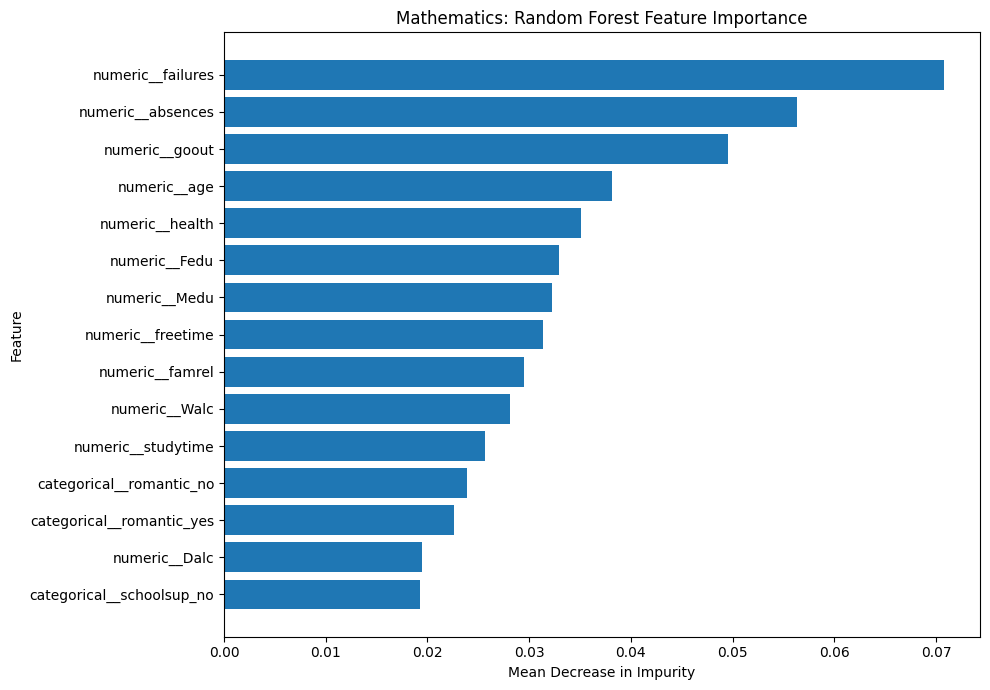


Top 10 SHAP features:
    Dataset  Rank                      Feature  Mean_Absolute_SHAP
Mathematics     1            numeric__failures            0.064598
Mathematics     2               numeric__goout            0.036261
Mathematics     3            numeric__absences            0.020648
Mathematics     4    categorical__schoolsup_no            0.014815
Mathematics     5                 numeric__age            0.014573
Mathematics     6           categorical__sex_F            0.014093
Mathematics     7                numeric__Medu            0.013508
Mathematics     8 categorical__guardian_father            0.013062
Mathematics     9   categorical__schoolsup_yes            0.012366
Mathematics    10           categorical__sex_M            0.012279


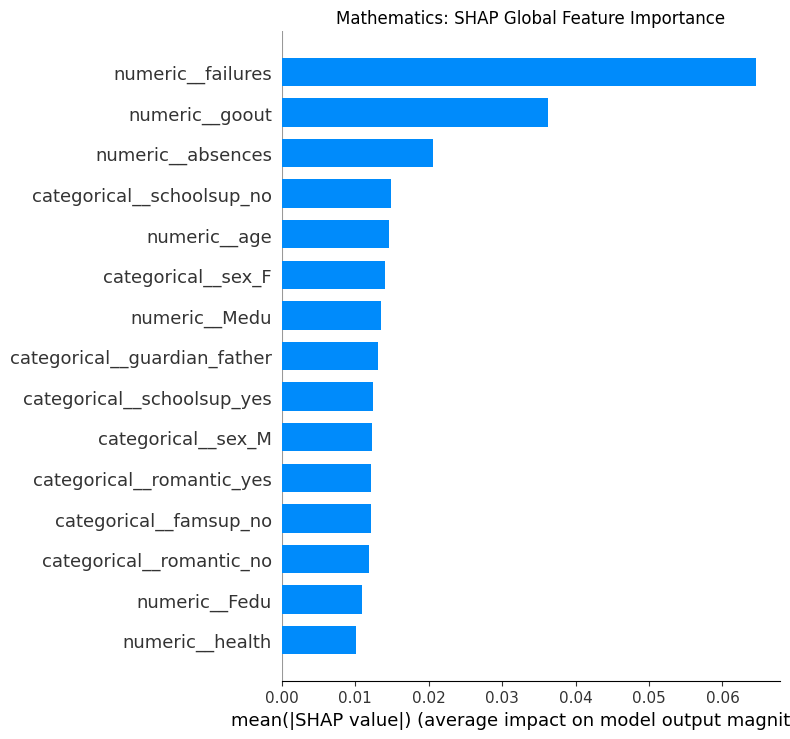

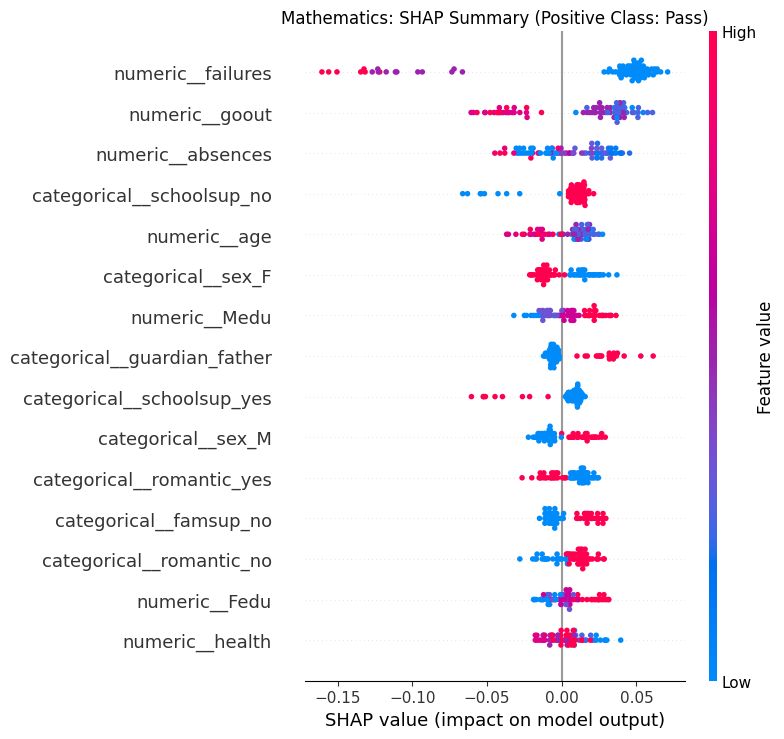


Saved model: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\models\explainability\mathematics_random_forest.joblib
Saved RF ranking: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\mathematics_random_forest_importance.csv
Saved RF plot: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\mathematics_random_forest_importance.png
Saved SHAP ranking: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\mathematics_shap_importance.csv
Saved SHAP importance plot: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\mathematics_shap_feature_importance.png
Saved SHAP summary: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\mathematics_shap_summary.png

DATASET: PORTUGUESE

Test-set metrics:
Accuracy: 0.7846
Precision: 0.8534
Recall: 0.9000
F1_Score: 0.8761
ROC_AUC: 0.6807

Classification report:
              precision    recall  f1-

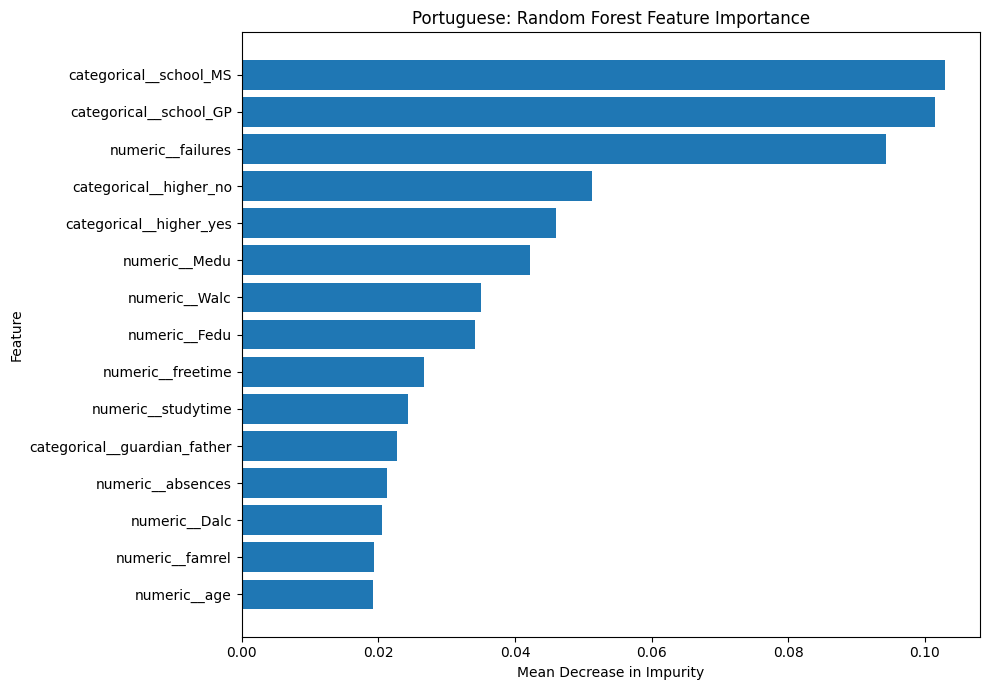


Top 10 SHAP features:
   Dataset  Rank                      Feature  Mean_Absolute_SHAP
Portuguese     1            numeric__failures            0.072863
Portuguese     2       categorical__school_MS            0.072612
Portuguese     3       categorical__school_GP            0.070802
Portuguese     4       categorical__higher_no            0.038151
Portuguese     5      categorical__higher_yes            0.033299
Portuguese     6                numeric__Fedu            0.024221
Portuguese     7                numeric__Medu            0.023672
Portuguese     8                numeric__Walc            0.020453
Portuguese     9 categorical__guardian_father            0.016857
Portuguese    10           numeric__studytime            0.016080


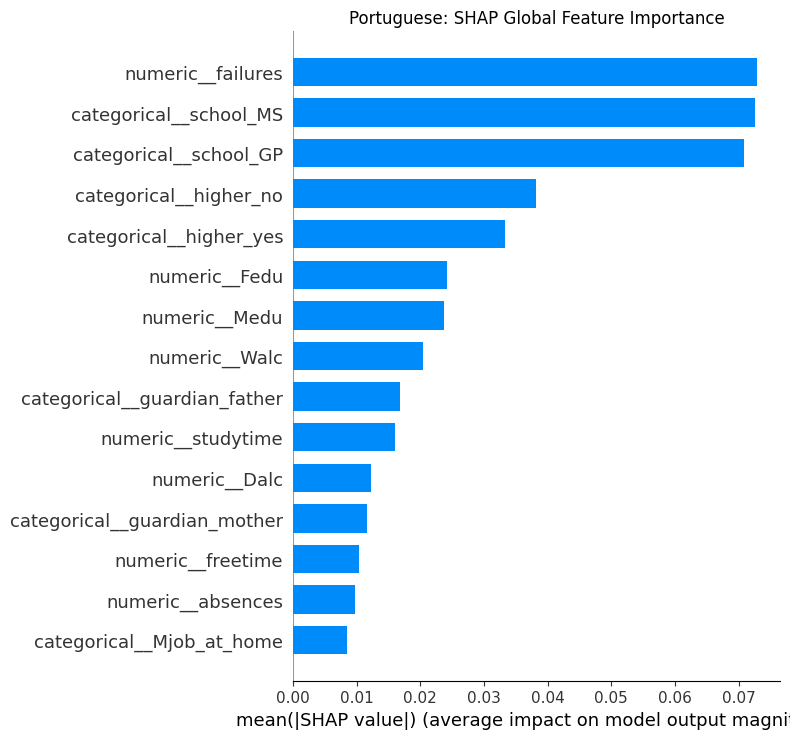

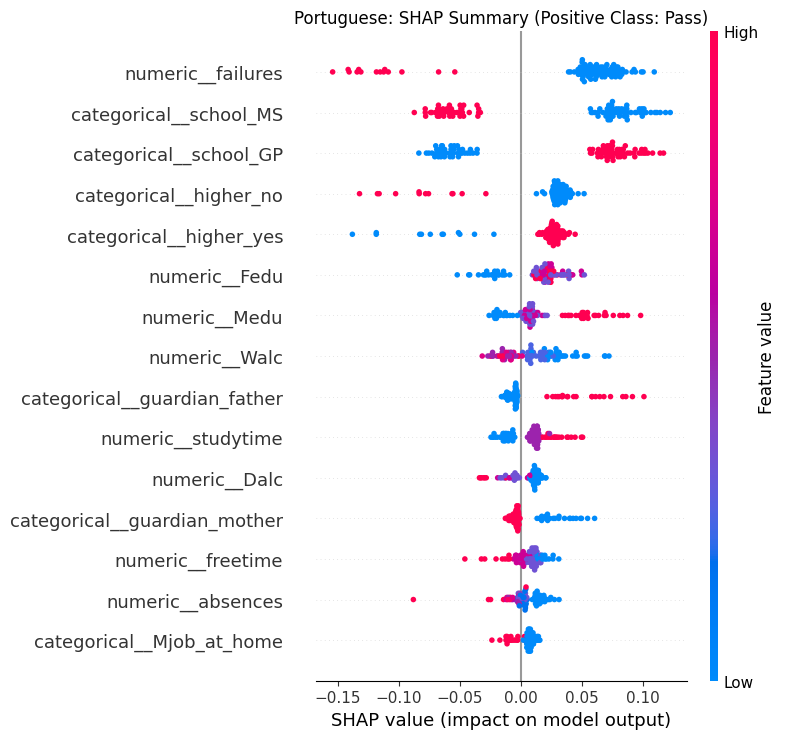


Saved model: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\models\explainability\portuguese_random_forest.joblib
Saved RF ranking: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\portuguese_random_forest_importance.csv
Saved RF plot: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\portuguese_random_forest_importance.png
Saved SHAP ranking: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\portuguese_shap_importance.csv
Saved SHAP importance plot: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\portuguese_shap_feature_importance.png
Saved SHAP summary: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\portuguese_shap_summary.png

PHASE 16 COMPLETED SUCCESSFULLY

Random Forest evaluation metrics:
    Dataset         Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
Mathematics Random Forest    0.6709     0.7143  0

,Dataset,Rank,Feature,Mean_Absolute_SHAP
0,Mathematics,1,numeric__failures,0.064598
1,Mathematics,2,numeric__goout,0.036261
2,Mathematics,3,numeric__absences,0.020648
3,Mathematics,4,categorical__schoolsup_no,0.014815
4,Mathematics,5,numeric__age,0.014573
5,Mathematics,6,categorical__sex_F,0.014093
6,Mathematics,7,numeric__Medu,0.013508
7,Mathematics,8,categorical__guardian_father,0.013062
8,Mathematics,9,categorical__schoolsup_yes,0.012366
9,Mathematics,10,categorical__sex_M,0.012279



Top 10 SHAP features — Portuguese:


,Dataset,Rank,Feature,Mean_Absolute_SHAP
56,Portuguese,1,numeric__failures,0.072863
57,Portuguese,2,categorical__school_MS,0.072612
58,Portuguese,3,categorical__school_GP,0.070802
59,Portuguese,4,categorical__higher_no,0.038151
60,Portuguese,5,categorical__higher_yes,0.033299
61,Portuguese,6,numeric__Fedu,0.024221
62,Portuguese,7,numeric__Medu,0.023672
63,Portuguese,8,numeric__Walc,0.020453
64,Portuguese,9,categorical__guardian_father,0.016857
65,Portuguese,10,numeric__studytime,0.016080



Saved combined RF importance: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\random_forest_feature_importance_all.csv
Saved combined SHAP ranking: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\shap_feature_importance_all.csv
Saved XAI metrics: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\xai_random_forest_metrics.csv
Figures directory: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures
Models directory: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\models\explainability

Interpretation note: feature importance describes model behavior; it does not establish causal relationships.


In [2]:

# ============================================================
# PHASE 16: EXPLAINABLE AI (XAI)
# Student Performance Prediction Using ML and SHAP
# ============================================================

from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. LOCATE PROJECT ROOT
# ============================================================

current_path = Path.cwd().resolve()
PROJECT_ROOT = None

for candidate in [current_path, *current_path.parents]:
    if (candidate / "data" / "processed" / "model_ready").is_dir():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/processed/model_ready. "
        "Open the notebook from your Student-Performance-Prediction project."
    )

MODEL_READY_DIR = PROJECT_ROOT / "data" / "processed" / "model_ready"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
MODELS_DIR = PROJECT_ROOT / "models" / "explainability"

for folder in [FIGURES_DIR, TABLES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("PHASE 16: EXPLAINABLE AI")
print("=" * 65)
print("Project root:", PROJECT_ROOT)
print("Model-ready data:", MODEL_READY_DIR)
print("Figures output:", FIGURES_DIR)
print("Tables output:", TABLES_DIR)
print("Models output:", MODELS_DIR)

# ============================================================
# 2. DEFINE ALL INPUT FILES AS PATH OBJECTS
# ============================================================

DATASETS = {
    "Mathematics": {
        "prefix": "mathematics",
        "X_train": MODEL_READY_DIR / "mat_X_train_balanced.csv",
        "y_train": MODEL_READY_DIR / "mat_y_train_balanced.csv",
        "X_test": MODEL_READY_DIR / "mat_X_test_processed.csv",
        "y_test": MODEL_READY_DIR / "mat_y_test.csv",
    },
    "Portuguese": {
        "prefix": "portuguese",
        "X_train": MODEL_READY_DIR / "por_X_train_balanced.csv",
        "y_train": MODEL_READY_DIR / "por_y_train_balanced.csv",
        "X_test": MODEL_READY_DIR / "por_X_test_processed.csv",
        "y_test": MODEL_READY_DIR / "por_y_test.csv",
    },
}

# Explicitly convert every path to pathlib.Path.
# This prevents: 'str' object has no attribute 'is_file'.

for dataset_name, dataset_paths in DATASETS.items():
    for key, value in dataset_paths.items():
        if key != "prefix":
            dataset_paths[key] = Path(value)

# ============================================================
# 3. CHECK ALL INPUT FILES BEFORE STARTING
# ============================================================

missing_files = []

for dataset_name, dataset_paths in DATASETS.items():
    for key, file_path in dataset_paths.items():
        if key == "prefix":
            continue

        if not file_path.is_file():
            missing_files.append(
                f"{dataset_name} / {key}: {file_path}"
            )

if missing_files:
    print("\nMissing input files:")
    for missing in missing_files:
        print("-", missing)

    raise FileNotFoundError(
        "\nRequired CSV files are missing. "
        "Check the filenames in data/processed/model_ready."
    )

print("\nAll eight required CSV files were found.")

# ============================================================
# 4. LOAD AND VALIDATE BOTH DATASETS
# ============================================================

loaded_data = {}

for dataset_name, dataset_paths in DATASETS.items():

    X_train = pd.read_csv(dataset_paths["X_train"])
    y_train = pd.read_csv(dataset_paths["y_train"]).squeeze("columns")
    X_test = pd.read_csv(dataset_paths["X_test"])
    y_test = pd.read_csv(dataset_paths["y_test"]).squeeze("columns")

    y_train = pd.Series(y_train).reset_index(drop=True).astype(int)
    y_test = pd.Series(y_test).reset_index(drop=True).astype(int)

    if list(X_train.columns) != list(X_test.columns):
        raise ValueError(
            f"{dataset_name}: training and test feature columns "
            "do not match in name or order."
        )

    if len(X_train) != len(y_train):
        raise ValueError(
            f"{dataset_name}: training features and labels have "
            "different row counts."
        )

    if len(X_test) != len(y_test):
        raise ValueError(
            f"{dataset_name}: test features and labels have "
            "different row counts."
        )

    if X_train.empty or X_test.empty:
        raise ValueError(f"{dataset_name}: an input dataset is empty.")

    if X_train.isna().any().any() or X_test.isna().any().any():
        raise ValueError(
            f"{dataset_name}: missing values found in feature data."
        )

    if not all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in X_train.dtypes
    ):
        raise TypeError(
            f"{dataset_name}: training features must be numeric."
        )

    if not all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in X_test.dtypes
    ):
        raise TypeError(
            f"{dataset_name}: test features must be numeric."
        )

    if set(y_train.unique()) != {0, 1}:
        raise ValueError(
            f"{dataset_name}: training labels must contain classes 0 and 1."
        )

    if not set(y_test.unique()).issubset({0, 1}):
        raise ValueError(
            f"{dataset_name}: unexpected test target labels."
        )

    loaded_data[dataset_name] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
    }

    print(f"\n{dataset_name} data loaded successfully.")
    print("Training feature shape:", X_train.shape)
    print("Test feature shape:", X_test.shape)
    print("Training class counts:", y_train.value_counts().to_dict())
    print("Test class counts:", y_test.value_counts().to_dict())

# ============================================================
# 5. TRAIN RANDOM FOREST, EVALUATE AND EXPLAIN
# ============================================================

all_rf_importance = []
all_shap_importance = []
all_metrics = []

MAX_EXPLANATION_ROWS = 100

for dataset_name, data in loaded_data.items():

    print("\n" + "=" * 65)
    print(f"DATASET: {dataset_name.upper()}")
    print("=" * 65)

    X_train = data["X_train"]
    y_train = data["y_train"]
    X_test = data["X_test"]
    y_test = data["y_test"]

    # Train using the balanced training data only.
    # The test set is not passed to fit().
    rf_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )

    rf_model.fit(X_train, y_train)

    # Test evaluation
    y_pred = rf_model.predict(X_test)
    y_probability = rf_model.predict_proba(X_test)[:, 1]

    metrics = {
        "Dataset": dataset_name,
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_probability),
    }

    all_metrics.append(metrics)

    print("\nTest-set metrics:")
    for metric_name, metric_value in metrics.items():
        if isinstance(metric_value, (int, float, np.number)):
            print(f"{metric_name}: {metric_value:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["At Risk (0)", "Pass (1)"],
            zero_division=0,
        )
    )

    # Save fitted Random Forest
    model_path = (
        MODELS_DIR / f"{dataset_name.lower()}_random_forest.joblib"
    )
    joblib.dump(rf_model, model_path)

    # --------------------------------------------------------
    # 5A. RANDOM FOREST FEATURE IMPORTANCE
    # --------------------------------------------------------

    rf_importance = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": rf_model.feature_importances_,
    }).sort_values("Importance", ascending=False).reset_index(drop=True)

    rf_importance.insert(
        0, "Rank", np.arange(1, len(rf_importance) + 1)
    )
    rf_importance.insert(0, "Dataset", dataset_name)

    rf_importance_path = (
        TABLES_DIR /
        f"{dataset_name.lower()}_random_forest_importance.csv"
    )
    rf_importance.to_csv(rf_importance_path, index=False)

    print("\nTop 10 Random Forest features:")
    print(rf_importance.head(10).to_string(index=False))

    top_rf = rf_importance.head(15).sort_values("Importance")

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top_rf["Feature"], top_rf["Importance"])
    ax.set_xlabel("Mean Decrease in Impurity")
    ax.set_ylabel("Feature")
    ax.set_title(f"{dataset_name}: Random Forest Feature Importance")
    fig.tight_layout()

    rf_plot_path = (
        FIGURES_DIR /
        f"{dataset_name.lower()}_random_forest_importance.png"
    )
    fig.savefig(rf_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 5B. SHAP EXPLANATIONS ON HELD-OUT TEST ROWS
    # --------------------------------------------------------

    X_explain = X_test.sample(
        n=min(MAX_EXPLANATION_ROWS, len(X_test)),
        random_state=42,
    )

    explainer = shap.TreeExplainer(rf_model)
    shap_output = explainer(X_explain)

    shap_values = np.asarray(shap_output.values)

    # Select class 1 (Pass) for binary classification.
    if shap_values.ndim == 3:
        if shap_values.shape[-1] == 2:
            shap_positive = shap_values[:, :, 1]
        elif shap_values.shape[0] == 2:
            shap_positive = shap_values[1, :, :]
        else:
            raise ValueError(
                f"Unexpected SHAP dimensions: {shap_values.shape}"
            )
    elif shap_values.ndim == 2:
        shap_positive = shap_values
    else:
        raise ValueError(
            f"Unsupported SHAP output shape: {shap_values.shape}"
        )

    if shap_positive.shape != X_explain.shape:
        raise ValueError(
            f"{dataset_name}: SHAP shape {shap_positive.shape} "
            f"does not match input shape {X_explain.shape}."
        )

    shap_importance = pd.DataFrame({
        "Feature": X_explain.columns,
        "Mean_Absolute_SHAP": np.abs(shap_positive).mean(axis=0),
    }).sort_values(
        "Mean_Absolute_SHAP", ascending=False
    ).reset_index(drop=True)

    shap_importance.insert(
        0, "Rank", np.arange(1, len(shap_importance) + 1)
    )
    shap_importance.insert(0, "Dataset", dataset_name)

    shap_importance_path = (
        TABLES_DIR /
        f"{dataset_name.lower()}_shap_importance.csv"
    )
    shap_importance.to_csv(shap_importance_path, index=False)

    print("\nTop 10 SHAP features:")
    print(shap_importance.head(10).to_string(index=False))

    # SHAP global importance bar plot
    shap.summary_plot(
        shap_positive,
        X_explain,
        plot_type="bar",
        max_display=15,
        show=False,
    )
    plt.title(f"{dataset_name}: SHAP Global Feature Importance")
    plt.tight_layout()

    shap_bar_path = (
        FIGURES_DIR /
        f"{dataset_name.lower()}_shap_feature_importance.png"
    )
    plt.savefig(shap_bar_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # SHAP summary plot showing direction and magnitude
    shap.summary_plot(
        shap_positive,
        X_explain,
        max_display=15,
        show=False,
    )
    plt.title(f"{dataset_name}: SHAP Summary (Positive Class: Pass)")
    plt.tight_layout()

    shap_summary_path = (
        FIGURES_DIR /
        f"{dataset_name.lower()}_shap_summary.png"
    )
    plt.savefig(shap_summary_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    all_rf_importance.append(rf_importance)
    all_shap_importance.append(shap_importance)

    print("\nSaved model:", model_path)
    print("Saved RF ranking:", rf_importance_path)
    print("Saved RF plot:", rf_plot_path)
    print("Saved SHAP ranking:", shap_importance_path)
    print("Saved SHAP importance plot:", shap_bar_path)
    print("Saved SHAP summary:", shap_summary_path)

# ============================================================
# 6. SAVE COMBINED TABLES FOR THE RESEARCH PAPER
# ============================================================

combined_rf = pd.concat(all_rf_importance, ignore_index=True)
combined_shap = pd.concat(all_shap_importance, ignore_index=True)
metrics_df = pd.DataFrame(all_metrics)

combined_rf_path = (
    TABLES_DIR / "random_forest_feature_importance_all.csv"
)
combined_shap_path = (
    TABLES_DIR / "shap_feature_importance_all.csv"
)
metrics_path = (
    TABLES_DIR / "xai_random_forest_metrics.csv"
)

combined_rf.to_csv(combined_rf_path, index=False)
combined_shap.to_csv(combined_shap_path, index=False)
metrics_df.to_csv(metrics_path, index=False)

print("\n" + "=" * 65)
print("PHASE 16 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nRandom Forest evaluation metrics:")
print(metrics_df.round(4).to_string(index=False))

for dataset_name in DATASETS:
    print(f"\nTop 10 SHAP features — {dataset_name}:")
    display(
        combined_shap[
            combined_shap["Dataset"] == dataset_name
        ].head(10)
    )

print("\nSaved combined RF importance:", combined_rf_path)
print("Saved combined SHAP ranking:", combined_shap_path)
print("Saved XAI metrics:", metrics_path)
print("Figures directory:", FIGURES_DIR)
print("Models directory:", MODELS_DIR)

print(
    "\nInterpretation note: feature importance describes model behavior; "
    "it does not establish causal relationships."
)


In [3]:

# PHASE 16: SHAP EXPLANATIONS FOR TUNED AT-RISK SVM MODELS
# This experiment is separate from the existing Random Forest analysis.

from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------
ROOT = Path.cwd().resolve()

while not (
    (ROOT / "data" / "processed" / "splits").is_dir()
    and (ROOT / "models" / "tuned_at_risk").is_dir()
):
    if ROOT.parent == ROOT:
        raise FileNotFoundError(
            "Open this notebook from the Student-Performance-Prediction project."
        )
    ROOT = ROOT.parent

SPLITS_DIR = ROOT / "data" / "processed" / "splits"
MODELS_DIR = ROOT / "models" / "tuned_at_risk"
FIGURES_DIR = ROOT / "results" / "figures"
TABLES_DIR = ROOT / "results" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Exact filenames verified in your project
DATASETS = {
    "Mathematics": {
        "x_train": "mat_X_train.csv",
        "x_test": "mat_X_test.csv",
        "model": "mathematics_svm.joblib",
    },
    "Portuguese": {
        "x_train": "por_X_train.csv",
        "x_test": "por_X_test.csv",
        "model": "portuguese_svm.joblib",
    },
}

# Keep the experiment reproducible and computationally manageable.
BACKGROUND_SIZE = 20
EXPLAIN_SIZE = 40
KERNEL_NSAMPLES = 100
RANDOM_STATE = 42

all_rankings = []

# --------------------------------------------------
# 2. LOAD EACH TUNED SVM AND EXPLAIN AT-RISK CLASS
# --------------------------------------------------
for dataset_name, config in DATASETS.items():
    print(f"\n{'=' * 60}")
    print(f"SHAP ANALYSIS: {dataset_name} — AT RISK")
    print("=" * 60)

    X_train = pd.read_csv(SPLITS_DIR / config["x_train"])
    X_test = pd.read_csv(SPLITS_DIR / config["x_test"])

    # Ensure training and test features match exactly.
    if list(X_train.columns) != list(X_test.columns):
        raise ValueError(
            f"Training/test feature mismatch for {dataset_name}."
        )

    feature_names = X_train.columns.tolist()

    model_path = MODELS_DIR / config["model"]
    if not model_path.is_file():
        raise FileNotFoundError(f"Missing model: {model_path}")

    pipeline = joblib.load(model_path)

    # KernelExplainer needs a numerical array, but the saved pipeline
    # receives a DataFrame with the original column names and values.
    rng = np.random.default_rng(RANDOM_STATE)

    background_n = min(BACKGROUND_SIZE, len(X_train))
    explain_n = min(EXPLAIN_SIZE, len(X_test))

    background_idx = rng.choice(
        len(X_train), size=background_n, replace=False
    )
    explain_idx = rng.choice(
        len(X_test), size=explain_n, replace=False
    )

    background = X_train.iloc[background_idx].copy()
    X_explain = X_test.iloc[explain_idx].copy()

    def predict_at_risk(values):
        """Return predicted probability for class 0 = At Risk."""
        frame = pd.DataFrame(values, columns=feature_names)
        probabilities = pipeline.predict_proba(frame)

        classes = list(pipeline.classes_)
        if 0 not in classes:
            raise ValueError(
                f"Expected At-Risk class 0; model classes are {classes}"
            )

        risk_column = classes.index(0)
        return probabilities[:, risk_column]

    explainer = shap.KernelExplainer(
        predict_at_risk,
        background.to_numpy(),
    )

    shap_values = explainer.shap_values(
        X_explain.to_numpy(),
        nsamples=KERNEL_NSAMPLES,
    )

    # Normalize SHAP output shape for a single-output probability function.
    shap_values = np.asarray(shap_values)
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 0]
    if shap_values.shape != (len(X_explain), len(feature_names)):
        raise ValueError(
            f"Unexpected SHAP shape for {dataset_name}: "
            f"{shap_values.shape}"
        )

    # --------------------------------------------------
    # 3. GLOBAL FEATURE RANKING
    # --------------------------------------------------
    ranking = pd.DataFrame({
        "Dataset": dataset_name,
        "Model": "Tuned SVM",
        "Feature": feature_names,
        "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0),
    }).sort_values("Mean_Absolute_SHAP", ascending=False)

    ranking["Rank"] = range(1, len(ranking) + 1)
    all_rankings.append(ranking)

    print("\nTop 10 features for At-Risk predictions:")
    print(
        ranking[
            ["Rank", "Feature", "Mean_Absolute_SHAP"]
        ].head(10).to_string(index=False)
    )

    # --------------------------------------------------
    # 4. SAVE GLOBAL IMPORTANCE BAR PLOT
    # --------------------------------------------------
    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        shap_values,
        X_explain,
        plot_type="bar",
        max_display=15,
        show=False,
    )
    plt.title(f"{dataset_name}: SVM SHAP Importance — At Risk")
    plt.tight_layout()

    bar_path = FIGURES_DIR / (
        f"{dataset_name.lower()}_svm_at_risk_shap_bar.png"
    )
    plt.savefig(bar_path, dpi=300, bbox_inches="tight")
    plt.close()

    # --------------------------------------------------
    # 5. SAVE SHAP SUMMARY PLOT
    # --------------------------------------------------
    shap.summary_plot(
        shap_values,
        X_explain,
        max_display=15,
        show=False,
    )
    plt.title(f"{dataset_name}: SVM SHAP Summary — At Risk")
    plt.tight_layout()

    summary_path = FIGURES_DIR / (
        f"{dataset_name.lower()}_svm_at_risk_shap_summary.png"
    )
    plt.savefig(summary_path, dpi=300, bbox_inches="tight")
    plt.close()

    print("Saved:", bar_path)
    print("Saved:", summary_path)

# --------------------------------------------------
# 6. SAVE COMBINED FEATURE RANKING
# --------------------------------------------------
combined_ranking = pd.concat(all_rankings, ignore_index=True)

ranking_path = TABLES_DIR / "at_risk_svm_shap_feature_ranking.csv"
combined_ranking.to_csv(ranking_path, index=False)

print("\n" + "=" * 60)
print("AT-RISK SVM SHAP ANALYSIS COMPLETED")
print("=" * 60)
print("Feature ranking:", ranking_path)
print("Figures directory:", FIGURES_DIR)
print(
    "\nInterpretation: SHAP values describe how features influence "
    "the model's predicted At-Risk probability. They do not prove causation."
)



SHAP ANALYSIS: Mathematics — AT RISK


  0%|          | 0/40 [00:00<?, ?it/s]


Top 10 features for At-Risk predictions:
 Rank    Feature  Mean_Absolute_SHAP
    1   failures            0.063594
    2       Mjob            0.049504
    3      goout            0.032955
    4       Walc            0.022034
    5 activities            0.019056
    6        sex            0.017666
    7   guardian            0.016953
    8     health            0.012904
    9       Medu            0.011890
   10  schoolsup            0.011346
Saved: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\mathematics_svm_at_risk_shap_bar.png
Saved: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\mathematics_svm_at_risk_shap_summary.png

SHAP ANALYSIS: Portuguese — AT RISK


  0%|          | 0/40 [00:00<?, ?it/s]


Top 10 features for At-Risk predictions:
 Rank  Feature  Mean_Absolute_SHAP
    1   school            0.147691
    2 failures            0.054204
    3   higher            0.039385
    4 guardian            0.031156
    5     Walc            0.027022
    6     Mjob            0.023987
    7  famsize            0.023425
    8 freetime            0.017834
    9   reason            0.017093
   10     Fjob            0.014193
Saved: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\portuguese_svm_at_risk_shap_bar.png
Saved: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures\portuguese_svm_at_risk_shap_summary.png

AT-RISK SVM SHAP ANALYSIS COMPLETED
Feature ranking: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\at_risk_svm_shap_feature_ranking.csv
Figures directory: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures

Interpretation: SHAP values describe how features inf

In [2]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nSplit directory:")
print(SPLITS_DIR)
print("Exists:", SPLITS_DIR.exists())

print("\nFiles Python can see:")
if SPLITS_DIR.exists():
    for file in sorted(SPLITS_DIR.iterdir()):
        print(repr(file.name))
else:
    print("Split directory does not exist.")

Current working directory:
e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\notebooks

Split directory:
E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\splits
Exists: True

Files Python can see:
'mat_X_test.csv'
'mat_X_train.csv'
'mat_y_test.csv'
'mat_y_train.csv'
'por_X_test.csv'
'por_X_train.csv'
'por_y_test.csv'
'por_y_train.csv'
